<a href="https://colab.research.google.com/github/edwardoughton/spatial_computing/blob/main/10_01_Scripting_Spatial_processing_via_GeoPandas_Part3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10: More on scripting for spatial analysis

Today we will use GeoPandas to answer some (basic) scientific research questions, for example, **how many buildings are within 500 meters of a park?**

For this question, we will download park polygons and buildings from Overture Maps. Then we will select one park, calculate its centroid, draw a buffer, intersect it with buildings, and count the results.

You can run the cells in order. We will keep working with GeoDataFrames throughout so as to not confuse you on the syntax. 

As I know some of you found the assignment hard, and weren't sure of how to get started, I'm focusing again on showing you how to work through some problems with you (rather than getting into graphs/shortest-path routing). 

## Set up

Run this installation cell once in a fresh Colab session. Downloads require an internet connection and may take a few minutes.

In [65]:
%pip -q install "overturemaps[geopandas]" matplotlib

Note: you may need to restart the kernel to use updated packages.


Import our tools. `geodataframe()` downloads an Overture layer as a GeoDataFrame, like those we used last week.

In [66]:
from overturemaps import geodataframe
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Download park polygons

Our search rectangle covers part of Fairfax, Virginia. 

The bounding box order is **west, south, east, north**, in longitude and latitude degrees.

Overture stores park boundaries in its `land_use` layer. 

We will download that layer, then select rows whose `subtype` is `park`. 

This gives us polygons from which we can calculate a centroid.

In [67]:
# Define a bounding box around the park area
# west, south, east, north
park_bbox = (-77.330, 38.835, -77.285, 38.875)
landuse = geodataframe("land_use", bbox=park_bbox)

In [68]:
# Inspect our data
print(landuse.head(1))

                                     id  \
0  3da5763a-7016-35b9-a271-0fd890551f85   

                                            geometry  \
0  POLYGON ((-77.33007 38.86166, -77.33155 38.859...   

                                             sources names  level wikidata  \
0  [{'property': '', 'dataset': 'OpenStreetMap', ...  None    NaN      NaN   

                source_tags      subtype        class  elevation surface  \
0  [(landuse, residential)]  residential  residential        NaN     NaN   

   version                                               bbox  
0        1  {'xmin': -77.33155822753906, 'xmax': -77.32792...  


Now we can select park records and keep their identifiers and geometries. 

The `.copy()` creates a separate GeoDataFrame. 

In [69]:
# Filter the landuse data to only include parks
parks = landuse.loc[landuse["subtype"] == "park", ["id", "geometry"]].copy()
print(len(parks))


35


In [70]:
# Drop any duplicate parks based on their unique ID and reset the index
parks = parks.drop_duplicates(subset="id")
parks = parks.reset_index(drop=True) # renumber the rows basically
len(parks)



35

In [71]:
# Inspect our parks data
parks.head()

,id,geometry
0,82e786b6-f9e1-3e3c-a578-6fefff998d72,"POLYGON ((-77.32589 38.87329, -77.32465 38.873..."
1,2d4be31a-d31f-3f3b-ae2b-8b80bea700d5,"POLYGON ((-77.32103 38.85907, -77.32117 38.858..."
2,9c6c401f-39e3-3014-b268-a9fa4db14199,"POLYGON ((-77.31415 38.86037, -77.31377 38.860..."
3,6c962b9e-78b3-3503-bb08-0f728e2cf531,"POLYGON ((-77.30363 38.86401, -77.30426 38.864..."
4,c6cfec73-8928-3edd-af50-c8a16d371333,"POLYGON ((-77.31511 38.87198, -77.3153 38.8720..."


If no parks are returned, stop here and ask for help (but you should have ~4).

Overture geometries use longitude and latitude. 

Assign that CRS only if it is missing, then transform to UTM Zone 18N (which Virginia resides within). 

This local projected CRS uses **meters**, which we need for a 500-meter buffer.

In [72]:
# First, reconfirm the CRS to WGS 84 (EPSG:4326)
parks = parks.set_crs("EPSG:4326") 

# Secondly, convert to UTM zone 18N (EPSG:32618) 
# This ensures accurate area calculations
parks = parks.to_crs("EPSG:32618") 

Now we can view the parks. 


These are projected coordinates in meters.

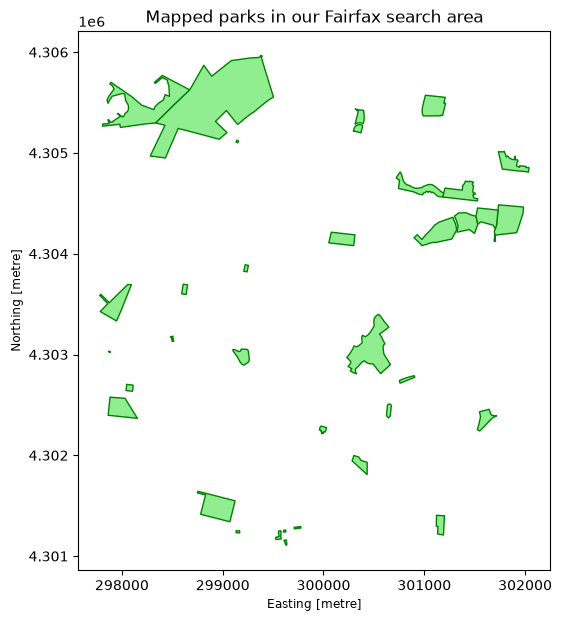

In [73]:
# Create our plot
ax = parks.plot(facecolor="lightgreen", edgecolor="green", figsize=(8, 7))
ax.set_title("Mapped parks in our Fairfax search area")
plt.show()

Let us add a basemap to make it look nice. 

In [74]:
%pip -q install contextily
import contextily as ctx

Note: you may need to restart the kernel to use updated packages.


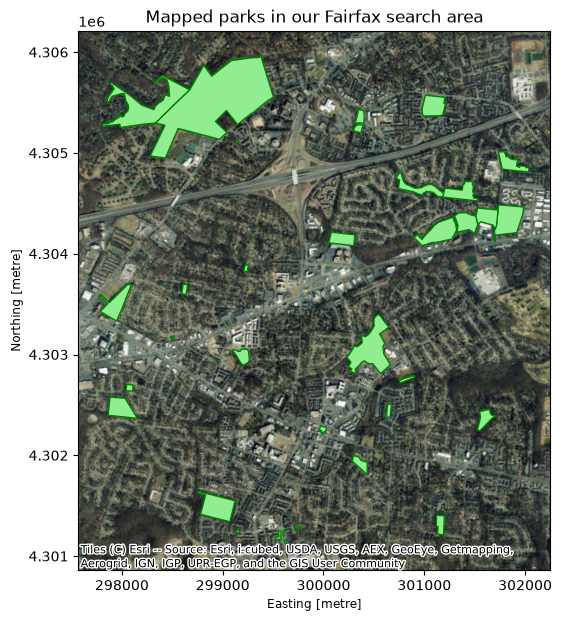

In [75]:
# Now add the contexily basemap to our plot
ax = parks.plot(facecolor="lightgreen", edgecolor="green", figsize=(8, 7))
ctx.add_basemap(ax, crs=parks.crs, source=ctx.providers.Esri.WorldImagery)
ax.set_title("Mapped parks in our Fairfax search area")
plt.show()

## 2. Select one park

Start with row 0. `.iloc[[0]]` selects the first row and keeps the result as a GeoDataFrame. 

The double brackets matter: we want a one-row layer, rather than an individual row.

This is a mapped park polygon, which may represent only part of a larger park. 

Record its ID so you know which feature you used.

Selected park ID: 82e786b6-f9e1-3e3c-a578-6fefff998d72


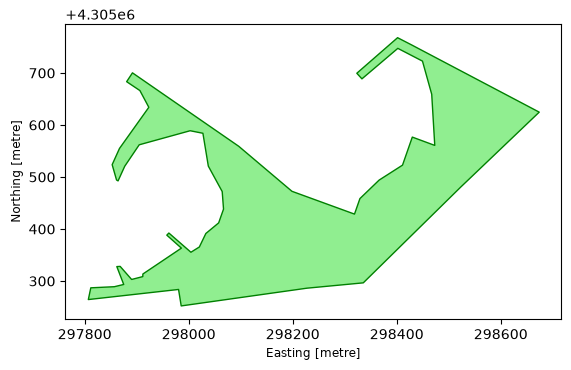

In [76]:
# Get the park in the first row of our GeoDataFrame
park = parks.iloc[[0]].copy()
print("Selected park ID:", park["id"].iloc[0])
park.plot(facecolor="lightgreen", edgecolor="green")
plt.show()

## 3. Find the centroid

A centroid is the geometric center of a shape. 

Copy the park layer, then replace its polygon geometry with its centroid point. The original `park` layer still contains the boundary.

A centroid is not necessarily a park entrance. For some shapes, it can even fall outside the park.

In [77]:
park_center = park.copy()
park_center["geometry"] = park.geometry.centroid
park_center

,id,geometry
0,82e786b6-f9e1-3e3c-a578-6fefff998d72,POINT (298250.074 4305462.016)


## 4. Create a 500-meter buffer

A buffer contains the area within a specified distance of a geometry. Buffering this point creates an approximately circular polygon.

Because our layer is projected in meters, `500` means 500 meters. 

This measures a straight line proximity to the centroid, rather than walking distance or distance from the park boundary.

In [78]:
# Set our buffer distance in meters and create the buffer
buffer_distance_m = 500
park_buffer = park_center.copy()
park_buffer["geometry"] = park_center.geometry.buffer(buffer_distance_m)
print(park_buffer['geometry'])

0    POLYGON ((298750.074 4305462.016, 298747.667 4...
Name: geometry, dtype: geometry


Plot the park, buffer, and centroid all together. 

Which parts of the park lie outside the circle?

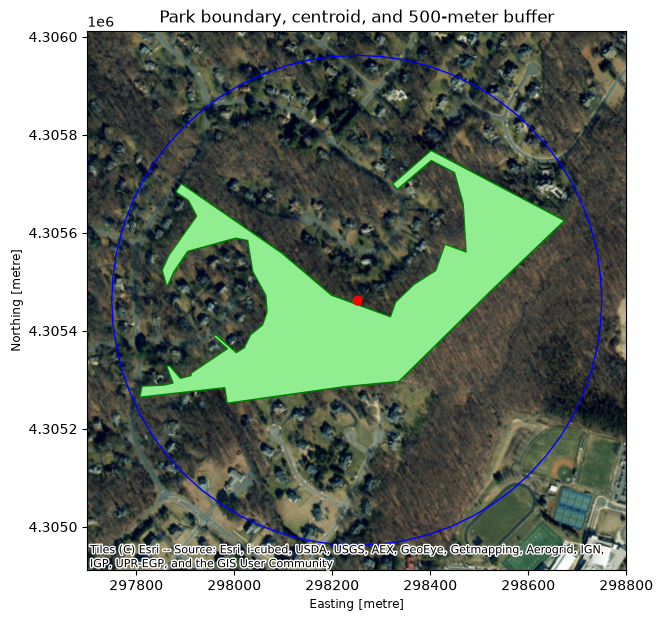

In [79]:
ax = park_buffer.plot(facecolor="none", edgecolor="blue", figsize=(8, 7))
park.plot(ax=ax, color="lightgreen", edgecolor="green")
park_center.plot(ax=ax, color="red", markersize=40)
ctx.add_basemap(ax, crs=parks.crs, source=ctx.providers.Esri.WorldImagery)
ax.set_title("Park boundary, centroid, and 500-meter buffer")
plt.show()

## 5. Download nearby buildings

We need a building search rectangle large enough to cover our whole buffer. 

Convert a copy of the buffer to longitude and latitude, then get its bounding box with `.total_bounds`.

This returns the same west, south, east, north order used by Overture. Our original buffer stays in meters.

In [80]:
buffer_lonlat = park_buffer.to_crs("EPSG:4326")
building_bbox = tuple(buffer_lonlat.total_bounds)
print("Building search rectangle:", building_bbox)

Building search rectangle: (np.float64(-77.33142919549395), np.float64(38.870372115821084), np.float64(-77.31991054753429), np.float64(38.87937622573386))


Download the buildings for this rectangle. Keep only their IDs and geometries, then remove repeated IDs so each mapped footprint is counted once.

In [81]:
buildings = geodataframe("building", bbox=building_bbox)
buildings = buildings[["id", "geometry"]].copy()
buildings = buildings.drop_duplicates(subset="id")
print("Downloaded building footprints:", len(buildings))

Downloaded building footprints: 161


Project the buildings to the **same CRS as the buffer** before intersecting them. Display a few rows to inspect the layer.

In [82]:
if buildings.crs is None:
    buildings = buildings.set_crs("EPSG:4326")
buildings = buildings.to_crs(parks.crs)
buildings.head()

,id,geometry
0,aaca938f-0b92-4a1c-8169-c76febb26b96,"POLYGON ((297781.102 4305702.583, 297772.151 4..."
1,59cb152a-ae84-4c32-86ce-ccab287a7d69,"POLYGON ((297824.425 4305706.796, 297812.898 4..."
2,85b9311d-8bc3-428d-bbea-62f5487506b9,"POLYGON ((297757.681 4305742.397, 297748.983 4..."
3,b94fe087-3eea-4292-a540-da5c49ae52d2,"POLYGON ((297849.307 4305729.617, 297841.474 4..."
4,7daf0f62-13d1-477c-b35b-afab0b6cc9eb,"POLYGON ((297818.724 4305755.831, 297810.403 4..."


## 6. Intersect buildings with the buffer

As in our earlier GeoPandas work, `.overlay(..., how="intersection")` keeps shared polygon area. 

Buildings crossing the circle are clipped at its boundary.

Keep only the buffer geometry in the second layer so its park ID is not confused with the building IDs. 

`keep_geom_type=True` keeps polygon results, so buildings that only touch the circle at a point or line are excluded.

In [83]:
nearby_buildings = buildings.overlay(
    park_buffer[["geometry"]],
    how="intersection",
    keep_geom_type=True,
)
print(nearby_buildings.head())
print(len(nearby_buildings), "buildings found within 500 meters of the park.")

                                     id  \
0  59cb152a-ae84-4c32-86ce-ccab287a7d69   
1  b94fe087-3eea-4292-a540-da5c49ae52d2   
2  2f67904d-2c0f-463f-8a12-85ac20cbaa01   
3  eef22855-9e15-477e-8a59-4050a65c41b0   
4  b3a95079-67d3-4dde-96c7-27f1b30c0b84   

                                            geometry  
0  POLYGON ((297824.425 4305706.796, 297823.922 4...  
1  POLYGON ((297841.192 4305717.807, 297840.356 4...  
2  POLYGON ((297964.49 4305792.479, 297967.786 43...  
3  POLYGON ((298032.283 4305818.047, 298017.348 4...  
4  POLYGON ((297915.763 4305831.295, 297914.844 4...  
124 buildings found within 500 meters of the park.


## 7. Count the buildings

Count unique building IDs using `.nunique()`. This counts each mapped footprint once, even if an intersection produces more than one piece.

Our rule includes buildings with any positive area overlap with the buffer, including partly covered buildings. It does not require the whole building to lie inside.

In [84]:
building_count = nearby_buildings["id"].nunique()
print("Building footprints intersecting the 500-meter buffer:", building_count)

Building footprints intersecting the 500-meter buffer: 124


## 8. Map the result

Show all downloaded buildings in gray and the intersecting portions in orange. The blue line is our buffer; the red point is the park centroid. If none intersect, the map still shows the buffer and downloaded features.

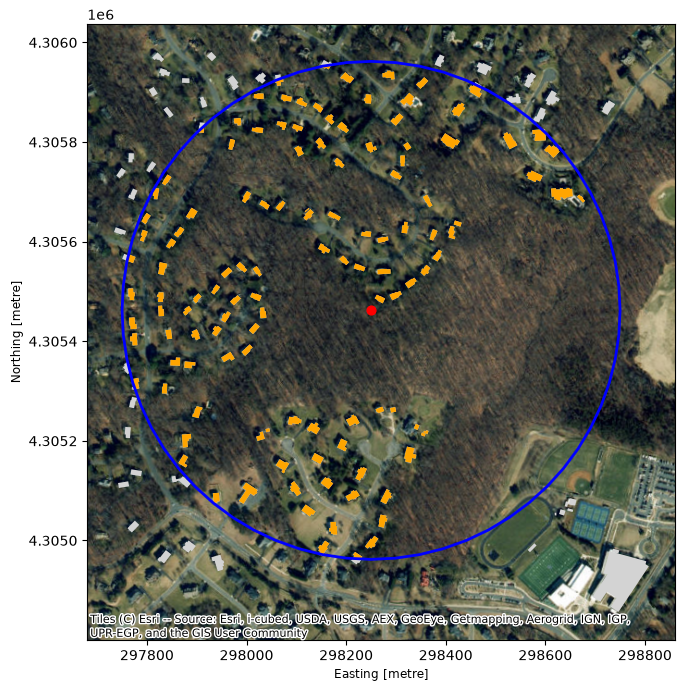

In [85]:
fig, ax = plt.subplots(figsize=(8, 8))
buildings.plot(ax=ax, color="lightgray")
nearby_buildings.plot(ax=ax, color="orange")
park_buffer.boundary.plot(ax=ax, color="blue", linewidth=2)
park_center.plot(ax=ax, color="red", markersize=40)
ctx.add_basemap(ax, crs=parks.crs, source=ctx.providers.Esri.WorldImagery)

Finish the same map in the next cell. `fig` and `ax` refer to the figure we just created. The title reports the count calculated by Python.

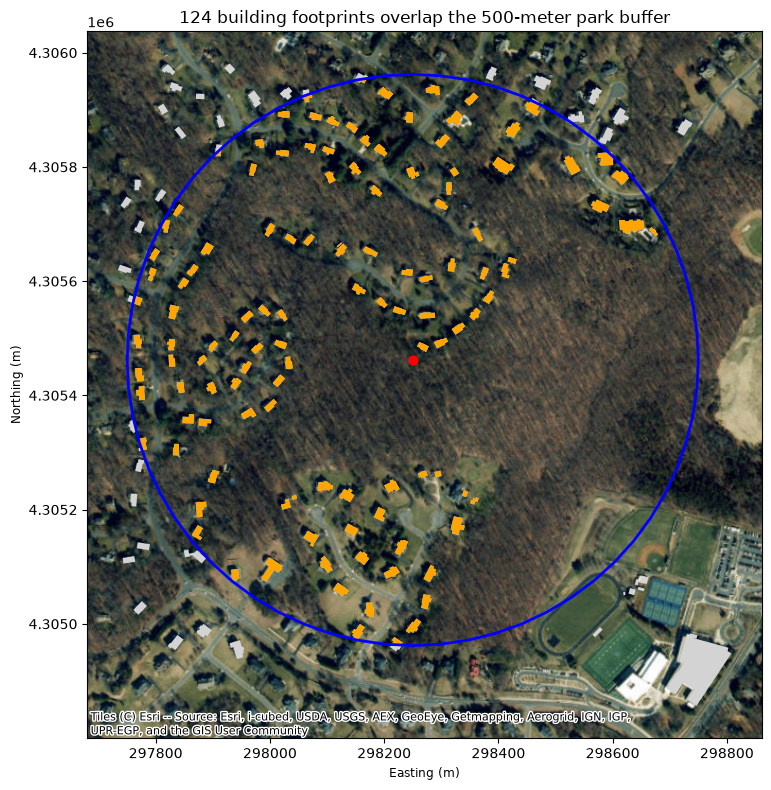

In [86]:
ax.set_title(f"{building_count} building footprints overlap the 500-meter park buffer")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
fig.tight_layout()
display(fig)
plt.close(fig)

## Exercise

How many buildings intersect a **250-meter** buffer around the same park centroid?

Repeat the buffer, intersection, and count steps. 

You can reuse `buildings`, as the original download already covers this smaller circle.


## Discuss your result

Write two or three sentences answering our original question. 

Include the count, the 250- and 500-meter distance, and one limitation.

Does this count tell us how many people can walk to the park? Consider building use, population, entrances, and barriers. 


## Exercise

Can you convert the building polygons to centroids?

What might be the advantages and disadvantages of doing this?

Does this change the result? Can you explain your answer?


# Exercise

How many mapped buildings intersect a 500-meter buffer around a school?